Predicted days for 50 pages: 10.0 days


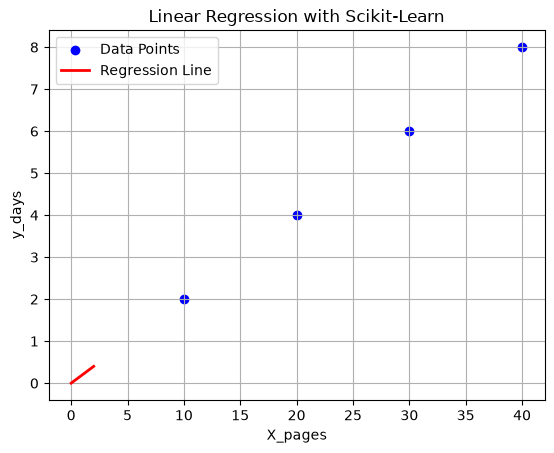

In [8]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt
# 1. Input Data (Must be 2D array for sklearn, Target is 1D)
X_pages = [[10], [20], [30], [40]]  # Page counts
y_days = [2, 4, 6, 8]             # Actual processing days

# 2. Train the Model
model = LinearRegression()
model.fit(X_pages, y_days)

# 3. Predict for a new file with 50 pages
new_file = [[50]]
predicted_days = model.predict(new_file)

print(f"Predicted days for 50 pages: {predicted_days[0]:.1f} days")
X_new = np.linspace(0, 2, 100).reshape(-1, 1)
y_predict = model.predict(X_new)

# 4. Plot the data points and the regression line
plt.scatter(X_pages, y_days, color="blue", label="Data Points")
plt.plot(X_new, y_predict, color="red", linewidth=2, label="Regression Line")

plt.xlabel("X_pages")
plt.ylabel("y_days")
plt.title("Linear Regression with Scikit-Learn")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

data = {
    'Income_Level': [2.5, 8.0, 3.0, 12.0],
    'Documents_Complete':[1,0,1,0],
    'Final_Decision': [1, 0, 1, 0]  # 1 = Approved, 0 = Rejected
}

df = pd.DataFrame(data)

X = df[['Income_Level', 'Documents_Complete']]
y = df['Final_Decision']

model = LogisticRegression()
model.fit(X, y)

new_applicant = pd.DataFrame([[3.5, 0]], columns=['Income_Level', 'Documents_Complete'])

prediction = model.predict(new_applicant)[0]
probability = model.predict_proba(new_applicant)[0]

decision_map = {1: "Approved", 0: "Rejected"}
print(f"Predicted Decision: {decision_map[prediction]} ({prediction})")
print(f"Confidence Level: Approved ({probability[1]:.2%}) | Rejected ({probability[0]:.2%})")


Predicted Decision: Approved (1)
Confidence Level: Approved (85.74%) | Rejected (14.26%)


In [13]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
data = {
    'Income_Level': [2.5, 8.0, 3.0, 12.0],
    'Documents_Complete':0,
    'Final_Decision': [1, 0, 1, 0]
}
df = pd.DataFrame(data)

X = df[['Income_Level', 'Documents_Complete']]
y = df['Final_Decision']

# 2. Train the Decision Tree Classifier
# We set random_state for reproducible splits
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X, y)

# 3. Predict for the new applicant (Income = 3.5, Documents = 1)
new_applicant = pd.DataFrame([[3.5, 1]], columns=['Income_Level', 'Documents_Complete'])
prediction = tree_model.predict(new_applicant)

decision_map = {1: "Approved", 0: "Rejected"}
print(f"Decision Tree Prediction: {decision_map[prediction[0]]}\n")

# 4. Plot the decision rules textually to see the exact logic
from sklearn.tree import export_text
tree_rules = export_text(tree_model, feature_names=list(X.columns))
print("Decision Tree Rules:")
print(tree_rules)

Decision Tree Prediction: Approved

Decision Tree Rules:
|--- Income_Level <= 5.50
|   |--- class: 1
|--- Income_Level >  5.50
|   |--- class: 0



In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate realistic data for Indian districts
np.random.seed(42)
n_districts = 150

# Three natural groups (e.g., Metro Hubs, Tier-2 Developing, Remote/Lagging)
group1_lit = np.random.normal(85, 5, 60)
group1_srv = np.random.normal(90, 6, 60)

group2_lit = np.random.normal(65, 6, 50)
group2_srv = np.random.normal(55, 7, 50)

group3_lit = np.random.normal(45, 5, 40)
group3_srv = np.random.normal(30, 5, 40)

literacy_rate = np.concatenate([group1_lit, group2_lit, group3_lit])
service_usage = np.concatenate([group1_srv, group2_srv, group3_srv])

df_districts = pd.DataFrame({
    'District_Name': [f"District_{i+1}" for i in range(n_districts)],
    'Digital_Literacy_Pct': np.clip(literacy_rate, 20, 100).round(1),
    'E_Governance_Usage_Pct': np.clip(service_usage, 10, 100).round(1)
})

In [26]:
df_districts.head()

,District_Name,Digital_Literacy_Pct,E_Governance_Usage_Pct
0,District_1,87.5,87.1
1,District_2,84.3,88.9
2,District_3,88.2,83.4
3,District_4,92.6,82.8
4,District_5,83.8,94.9


In [27]:
df_districts.describe()

,Digital_Literacy_Pct,E_Governance_Usage_Pct
count,150.000000,150.000000
mean,67.489333,62.530667
std,16.595488,25.331266
min,34.900000,13.800000
25%,55.450000,37.975000
50%,68.300000,58.750000
75%,82.700000,88.675000
max,94.300000,100.000000


In [28]:
df_districts.tail()

,District_Name,Digital_Literacy_Pct,E_Governance_Usage_Pct
145,District_146,42.6,26.5
146,District_147,51.3,34.5
147,District_148,41.5,31.5
148,District_149,47.2,34.1
149,District_150,48.9,33.1


<Axes: >

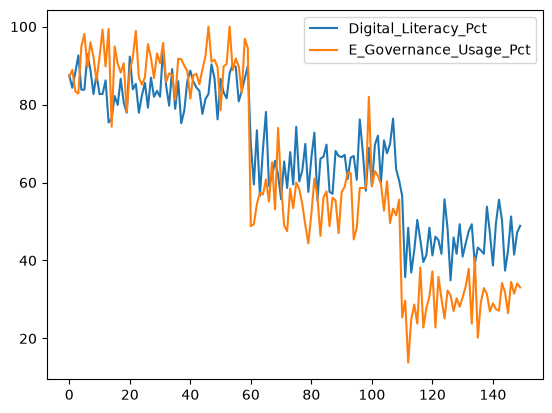

In [31]:

df_districts.plot()

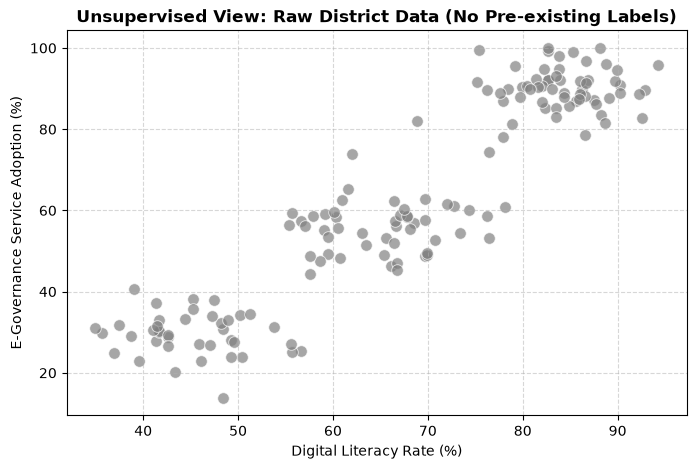

In [37]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_districts, 
    x='Digital_Literacy_Pct', 
    y='E_Governance_Usage_Pct', 
    color='gray', 
    alpha=0.7, 
    s=70
)
plt.title("Unsupervised View: Raw District Data (No Pre-existing Labels)", fontsize=12, fontweight='bold')
plt.xlabel("Digital Literacy Rate (%)")
plt.ylabel("E-Governance Service Adoption (%)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [38]:
from sklearn.cluster import KMeans
# 1. Select the features for clustering
X = df_districts[['Digital_Literacy_Pct', 'E_Governance_Usage_Pct']]

# 2. Apply K-Means to find K=3 distinct clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_districts['Cluster_ID'] = kmeans.fit_predict(X)
df_districts

,District_Name,Digital_Literacy_Pct,E_Governance_Usage_Pct,Cluster_ID
0,District_1,87.5,87.1,0
1,District_2,84.3,88.9,0
2,District_3,88.2,83.4,0
3,District_4,92.6,82.8,0
4,District_5,83.8,94.9,0
...,...,...,...,...
145,District_146,42.6,26.5,1
146,District_147,51.3,34.5,1
147,District_148,41.5,31.5,1
148,District_149,47.2,34.1,1


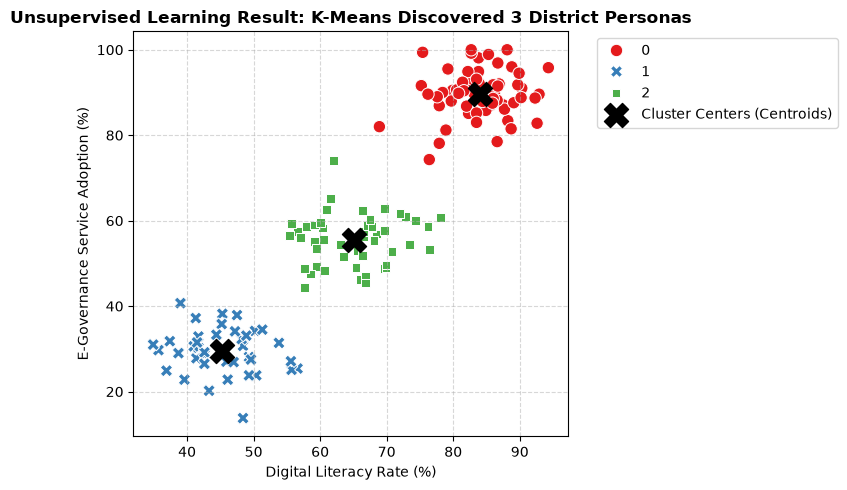

In [39]:
# Extract cluster centers (centroids)
centroids = kmeans.cluster_centers_

# 3. Plot the clustered results with Seaborn
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_districts, 
    x='Digital_Literacy_Pct', 
    y='E_Governance_Usage_Pct', 
    hue='Cluster_ID', 
    palette='Set1', 
    s=80, 
    style='Cluster_ID'
)

# Plot the central 'brain' (centroids) of each cluster
plt.scatter(
    centroids[:, 0], centroids[:, 1], 
    s=300, c='black', marker='X', label='Cluster Centers (Centroids)'
)

plt.title("Unsupervised Learning Result: K-Means Discovered 3 District Personas", fontsize=12, fontweight='bold')
plt.xlabel("Digital Literacy Rate (%)")
plt.ylabel("E-Governance Service Adoption (%)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [56]:
 # Or "jax" or "tensorflow"

from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Load the model
model = load_model("keras_Model.h5", compile=False)

# Load the labels
class_names = open("labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("<IMAGE_PATH>").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'keras_Model.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Generate realistic e-governance district data
np.random.seed(42)
n_districts = 400

internet_penetration = np.random.uniform(20, 95, n_districts) # %
literacy_rate = np.random.uniform(40, 99, n_districts)         # %
avg_bandwidth = np.random.exponential(15, n_districts)        # Mbps
public_kiosks = np.random.randint(1, 25, n_districts)         # Count per 10k citizens

# Define a non-linear policy success rule (Success = 1, Lagging = 0)
# Districts succeed if they have strong infrastructure OR balanced literacy + internet
success_rule = (
    ((internet_penetration > 60) & (literacy_rate > 70)) | 
    (public_kiosks > 18) | 
    ((avg_bandwidth > 22) & (literacy_rate > 60))
)
y = success_rule.astype(int)

# Combine into a feature matrix X
X = np.column_stack([internet_penetration, literacy_rate, avg_bandwidth, public_kiosks])

# 2. Split into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)

# 3. Scale features (Important for Neural Networks so larger numbers don't dominate)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Build & Train the Artificial Neural Network (ANN)
# Two hidden layers: 10 neurons in layer 1, 5 neurons in layer 2
model = MLPClassifier(
    hidden_layer_sizes=(10, 5), 
    activation='relu', 
    max_iter=2000, 
    random_state=42
)
model.fit(X_train_scaled, y_train)

# 5. Evaluate Performance
y_pred = model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print(f"🏛️ E-Governance ANN District Success Prediction Accuracy: {acc * 100:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Lagging (0)', 'High Success (1)']))

🏛️ E-Governance ANN District Success Prediction Accuracy: 90.00%

--- Classification Report ---
                  precision    recall  f1-score   support

     Lagging (0)       0.90      0.90      0.90        21
High Success (1)       0.89      0.89      0.89        19

        accuracy                           0.90        40
       macro avg       0.90      0.90      0.90        40
    weighted avg       0.90      0.90      0.90        40



In [2]:
!pip install opencv_python

   ---------------------------------------- 0.0/48.0 MB ? eta -:--:--
    --------------------------------------- 0.8/48.0 MB 7.0 MB/s eta 0:00:07
   - -------------------------------------- 2.4/48.0 MB 9.9 MB/s eta 0:00:05
   --- ------------------------------------ 4.7/48.0 MB 10.0 MB/s eta 0:00:05
   ----- ---------------------------------- 7.1/48.0 MB 9.7 MB/s eta 0:00:05
   ------- -------------------------------- 9.2/48.0 MB 10.0 MB/s eta 0:00:04
   --------- ------------------------------ 11.3/48.0 MB 9.8 MB/s eta 0:00:04
   ----------- ---------------------------- 13.4/48.0 MB 9.9 MB/s eta 0:00:04
   ------------ --------------------------- 15.5/48.0 MB 9.9 MB/s eta 0:00:04
   -------------- ------------------------- 17.6/48.0 MB 9.9 MB/s eta 0:00:04
   ---------------- ----------------------- 19.9/48.0 MB 9.9 MB/s eta 0:00:03
   ------------------ --------------------- 22.0/48.0 MB 10.0 MB/s eta 0:00:03
   -------------------- ------------------- 24.1/48.0 MB 10.0 MB/s eta 0:0


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [7]:
im=cv2.imread(r"C:\Users\nicsu\OneDrive\Pictures\Screenshots\a.png")
print(type(im))

<class 'numpy.ndarray'>


In [1]:
gray_image = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

# 3. Resize the image to 400x300 pixels
resized_image = cv2.resize(gray_image, (400, 300))

# 4. Detect edges using the Canny algorithm
edges = cv2.Canny(resized_image, threshold1=100, threshold2=200)

# 5. Display the result in a window
cv2.imshow('Detected Edges', im)
cv2.waitKey(0)  # Wait indefinitely until a key is pressed
cv2.destroyAllWindows()  # Close the window

# 6. Save the processed image to disk
cv2.imwrite('output_edges.jpg', edges)

NameError: name 'cv2' is not defined

In [14]:
print(im.shape)

(666, 1772, 3)


In [25]:
img_resize = cv2.resize(im, (300, 200), interpolation=cv2.INTER_AREA)
img_flip = cv2.flip(im,0)
cv2.cvtColor(img_resize,cv2.COLOR_BGR2GRAY)
cv2.imshow('imgage',im)
cv2.waitKey(0)  # Wait indefinitely until a key is pressed
cv2.destroyAllWindows()  # Close the window

# 6. Save the processed image to disk
cv2.imwrite('output_edges.jpg', edges)

True

In [26]:

img_crop=im[100:300,200:500]
cv2.imshow("Bootcamp",img_crop)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [29]:
!pip install ultralytics opencv-python
import cv2
from ultralytics import settings

# Disable data and crash report tracking
settings.update({"sync": False})
from ultralytics import YOLO

# 1. Load the lightweight YOLOv8 Nano model (~6MB, runs fast on CPU)
model = YOLO('yolov8n.pt')

# 2. Open the webcam (0 is default built-in camera)
cap = cv2.VideoCapture(0)

print("Starting Object Counter... Press 'q' on the video window to quit.")

while cap.isOpened():
  success, frame = cap.read()
  if not success:
    print("Failed to grab camera frame.")
    break

  # 3. Perform object detection on the current frame
  results = model(frame, verbose=False)

  # Get total number of objects detected in this frame
  detected_count = len(results[0].boxes)

  # 4. Render detection boxes directly on the frame
  annotated_frame = results[0].plot()

  # 5. Display the object count overlay on screen
  cv2.putText(
      annotated_frame,
      f'Total Objects Counted: {detected_count}',
      (20, 50),  # Position (x, y)
      cv2.FONT_HERSHEY_SIMPLEX,
      1,  # Font scale
      (0, 255, 0),  # Text color (Green)
      2,  # Thickness
      cv2.LINE_AA,
  )

  # 6. Show the frame in a window
  cv2.imshow('BCA AI Demo - Live Object Counter', annotated_frame)

  # 7. Terminate program cleanly when pressing 'q'
  if cv2.waitKey(1) & 0xFF == ord('q'):
    print("Terminating program...")
    break

# Release camera and close all windows cleanly
cap.release()

# 2. Add short wait key loops to let Windows pump destroy events cleanly
cv2.waitKey(1)
cv2.destroyAllWindows()
cv2.waitKey(1)

print("Camera feed closed successfully.")


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Starting Object Counter... Press 'q' on the video window to quit.


KeyboardInterrupt: 

In [ ]:
cv2.destroyAllWindows()

In [30]:
cap.release()
cv2.destroyAllWindows()

In [31]:
!pip install nltk


   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------------------------ --------- 1.3/1.7 MB 7.7 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 7.7 MB/s  0:00:00

   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------- ----------------------------- 1/4 [regex]
   ---------- ----------------------------- 1/4 [regex]
   -------------------- ------------------- 2/4 [click]
   -------------------- ------------------- 2/4 [click]
   -------------------- ------------------- 2/4 [click]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ---


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import nltk
nltk.download()

showing info https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/index.xml


KeyboardInterrupt: 

In [3]:
print("dfvnfkjbnvf")

dfvnfkjbnvf


In [4]:
!pip install spacy
!python -m spacy download en_core_web_sm

   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   --- ------------------------------------ 1.3/15.2 MB 8.5 MB/s eta 0:00:02
   ------- -------------------------------- 2.9/15.2 MB 8.9 MB/s eta 0:00:02
   ----------- ---------------------------- 4.5/15.2 MB 9.0 MB/s eta 0:00:02
   ----------- ---------------------------- 4.5/15.2 MB 9.0 MB/s eta 0:00:02
   ------------ --------------------------- 4.7/15.2 MB 5.8 MB/s eta 0:00:02
   ------------- -------------------------- 5.0/15.2 MB 4.6 MB/s eta 0:00:03
   --------------- ------------------------ 6.0/15.2 MB 4.2 MB/s eta 0:00:03
   ------------------- -------------------- 7.6/15.2 MB 4.6 MB/s eta 0:00:02
   -------------------------- ------------- 10.0/15.2 MB 5.4 MB/s eta 0:00:01
   -------------------------------- ------- 12.3/15.2 MB 6.0 MB/s eta 0:00:01
   -------------------------------------- - 14.7/15.2 MB 6.5 MB/s eta 0:00:01
   ---------------------------------------- 15.2/15.2 MB 6.5 MB/s  0:00:02
   --


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     ----- ---------------------------------- 1.8/12.8 MB 7.4 MB/s eta 0:00:02
     ------ --------------------------------- 2.1/12.8 MB 7.7 MB/s eta 0:00:02
     ------------- -------------------------- 4.5/12.8 MB 7.0 MB/s eta 0:00:02
     ------------------- -------------------- 6.3/12.8 MB 7.5 MB/s eta 0:00:01
     -------------------------- ------------- 8.4/12.8 MB 7.8 MB/s eta 0:00:01
     ------------------------------- -------- 10.2/12.8 MB 8.1 MB/s eta 0:00:01
     ------------------------------------- -- 12.1/12.8 MB 8.3 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 8.0 MB/s  0:00:01
[+] Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import spacy

# Load spaCy's lightweight English core model (~12MB)
nlp = spacy.load("en_core_web_sm")

# Sample unstructured text input
raw_resume_text = """
jitendra is a Software Developer living in New Delhi. 
He worked at Mantra Labs for 3 years starting from March 2021. 
jitendra graduated from IIT Roorkee and has expertise in JAVA, Machine Learning and AWS.
"""

print("Processing text with spaCy...\n")
doc = nlp(raw_resume_text)

print("--- Extracted Named Entities ---")
# Extract entities like Persons, Organizations, Locations, and Dates
for ent in doc.ents:
  print(f"Entity: {ent.text:<20} | Type: {ent.label_:<10} ({spacy.explain(ent.label_)})")

print("\n--- Identified Keywords/Nouns ---")
# Extract key nouns/skills
nouns = [token.text for token in doc if token.pos_ in ["NOUN", "PROPN"]]
print("Key Nouns Found:", list(set(nouns)))

Processing text with spaCy...

--- Extracted Named Entities ---
Entity: jitendra             | Type: PERSON     (People, including fictional)
Entity: Software             | Type: ORG        (Companies, agencies, institutions, etc.)
Entity: New Delhi            | Type: GPE        (Countries, cities, states)
Entity: Mantra Labs          | Type: ORG        (Companies, agencies, institutions, etc.)
Entity: 3 years              | Type: DATE       (Absolute or relative dates or periods)
Entity: March 2021           | Type: DATE       (Absolute or relative dates or periods)
Entity: jitendra             | Type: PERSON     (People, including fictional)
Entity: IIT                  | Type: ORG        (Companies, agencies, institutions, etc.)
Entity: JAVA                 | Type: ORG        (Companies, agencies, institutions, etc.)
Entity: Machine Learning     | Type: PERSON     (People, including fictional)

--- Identified Keywords/Nouns ---
Key Nouns Found: ['Software', 'Delhi', 'jitendra', 'Roo

In [7]:
!pip install wordcloud


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
from transformers import pipeline

# Load the FLAN model
chatbot = pipeline("text2text-generation", model="google/flan-t5-small")

# Few-shot example-based prompt
def get_kalam_response(user_input):
    prompt = f"""
    Answer like Dr. APJ Abdul Kalam.

    Q: Who is the Missile Man of India?
    A: Dr. APJ Abdul Kalam is known as the Missile Man of India for his significant contributions to India's missile programs.

    Q: Who is Swami Vivekananda?
    A: Swami Vivekananda was a spiritual leader who represented Indian philosophy and values globally and inspired youth across the world.

    Q: Who is APJ Abdul Kalam?
    A: Dr. APJ Abdul Kalam was the 11th President of India, a brilliant scientist, and a beloved teacher known for his vision of a developed India.

    Q: {user_input}
    A:"""

    result = chatbot(prompt, max_length=150, do_sample=False)[0]['generated_text']
    return result.strip()

# CLI loop
print("Welcome to Dr. Kalam Chatbot. Type 'exit' to stop.")
while True:
    user_input = input("You: ")
    if user_input.lower() in ['exit', 'quit']:
        break
    reply = get_kalam_response(user_input)
    print(f"Dr. Kalam: {reply}")

ModuleNotFoundError: No module named 'transformers'

In [9]:
!pip install "transformers[torch]"

   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/13.3 MB 4.6 MB/s eta 0:00:03
   ---- ----------------------------------- 1.6/13.3 MB 7.8 MB/s eta 0:00:02
   ------- -------------------------------- 2.4/13.3 MB 4.3 MB/s eta 0:00:03
   ----------- ---------------------------- 3.9/13.3 MB 5.4 MB/s eta 0:00:02
   ------------------ --------------------- 6.3/13.3 MB 6.7 MB/s eta 0:00:02
   -------------------------- ------------- 8.9/13.3 MB 7.7 MB/s eta 0:00:01
   ---------------------------------- ----- 11.5/13.3 MB 8.4 MB/s eta 0:00:01
   ---------------------------------------  13.1/13.3 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------- 13.3/13.3 MB 8.1 MB/s  0:00:01
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ---------------------------------------- 857.0/857.0 kB 11.2 MB/s  0:00:00
   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import torch
from transformers import pipeline

model_id = "CoRover/BharatGPT-3B-Indic"
pipe = pipeline(
    "text-generation",
    model=model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    trust_remote_code=True
)
messages = [
    {"role": "system", "content": "You are a helpful assistant who responds in English"},
    {"role": "user", "content": "who created you?"},
]
outputs = pipe(
    messages,
    max_new_tokens=256,
)
print(outputs[0]["generated_text"][-1])

OSError: You are trying to access a gated repo.
Make sure to have access to it at https://huggingface.co/CoRover/BharatGPT-3B-Indic.
401 Client Error. (Request ID: Root=1-6affda14-23e886a272531c5a27d4faa6;76c23865-326f-4772-9153-95b143d903f4)

Cannot access gated repo for url https://huggingface.co/CoRover/BharatGPT-3B-Indic/resolve/f7310f30f3fa92fa40d0df72250136378c3d0396/config.json.
Access to model CoRover/BharatGPT-3B-Indic is restricted. You must have access to it and be authenticated to access it. Please log in.

In [2]:
!pip install --upgrade gradio

   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   - -------------------------------------- 1.3/31.4 MB 9.1 MB/s eta 0:00:04
   -- ------------------------------------- 2.1/31.4 MB 6.5 MB/s eta 0:00:05
   ----- ---------------------------------- 4.2/31.4 MB 7.6 MB/s eta 0:00:04
   -------- ------------------------------- 6.6/31.4 MB 8.8 MB/s eta 0:00:03
   ----------- ---------------------------- 9.2/31.4 MB 9.5 MB/s eta 0:00:03
   -------------- ------------------------- 11.5/31.4 MB 9.9 MB/s eta 0:00:03
   ----------------- ---------------------- 13.9/31.4 MB 10.2 MB/s eta 0:00:02
   --------------------- ------------------ 16.5/31.4 MB 10.4 MB/s eta 0:00:02
   ------------------------ --------------- 18.9/31.4 MB 10.6 MB/s eta 0:00:02
   --------------------------- ------------ 21.2/31.4 MB 10.7 MB/s eta 0:00:01
   ------------------------------ --------- 23.9/31.4 MB 10.8 MB/s eta 0:00:01
   --------------------------------- ------ 26.2/31.4 MB 10.9 MB/s eta 0


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:

def alternatingly_agree(message, history):
    if len([h for h in history if h['role'] == "assistant"]) % 2 == 0:
        return f"Yes, I do think that: {message}"
    else:
        return "I don't think so"

gr.ChatInterface(
    fn=alternatingly_agree, 
).launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [7]:
import gradio as gr

gr.ChatInterface(
    fn=random_response, 
).launch()

NameError: name 'random_response' is not defined